# 08 · Fast vs slow — the demo

**Run order:** 01 → … → 06 → **08** (07 is reserved for the OpenSim re-run on the new strides). Needs
`Results/cohort_events.pkl`.

One notebook to *show* someone how fast and slow sprinters differ: the speed curves, the bodies themselves at
matching instants of the stride, and the few angle curves that separate the groups. Design rules used throughout:
**blue = faster, red = slower** (the repo-wide convention), left limbs faint, one message per panel, axes in
plain units.

**Read the comparison honestly.** The 5 fastest runners are all men and the 5 slowest all women, so the pooled
contrast mixes speed with sex; the within-sex section at the end is the fair version of the same question.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cohort as C
import sprint_pipeline as SP
import sprint_outputs as OUT

data = C.load()
F, cycles, runs = data["features"], data["cycles"], data["runs"]
y = F.top_speed_ms

N = 5
fast_ids = list(y.sort_values(ascending=False).index[:N])
slow_ids = list(y.sort_values().index[:N])
print(f"fast: {fast_ids} ({y[fast_ids].mean():.2f} m/s, sexes {''.join(F.sex[fast_ids])})")
print(f"slow: {slow_ids} ({y[slow_ids].mean():.2f} m/s, sexes {''.join(F.sex[slow_ids])})")

fast: ['SB50', 'SB101', 'SB82', 'SB155', 'SB061'] (9.14 m/s, sexes MMMMM)
slow: ['SB202', 'SB80', 'SB153', 'SB110', 'SB81'] (7.10 m/s, sexes FFFFF)


## 1 · The headline numbers

In [2]:
cols = ["top_speed_ms", "time_to_60m_s", "top_contact_ms", "top_flight_ms",
        "top_stride_length_m", "top_stride_frequency_hz", "height_m", "block_time_s"]
pd.DataFrame({"fastest 5": F.loc[fast_ids, cols].mean(), "slowest 5": F.loc[slow_ids, cols].mean(),
              "gap": F.loc[fast_ids, cols].mean() - F.loc[slow_ids, cols].mean()}).round(2)

,fastest 5,slowest 5,gap
top_speed_ms,9.14,7.10,2.05
time_to_60m_s,7.55,9.53,-1.98
top_contact_ms,74.00,107.33,-33.33
top_flight_ms,153.67,136.67,17.00
top_stride_length_m,4.12,3.41,0.71
top_stride_frequency_hz,2.21,2.08,0.13
height_m,1.83,1.69,0.14
block_time_s,0.23,0.29,-0.06


## 2 · The whole run: speed against distance

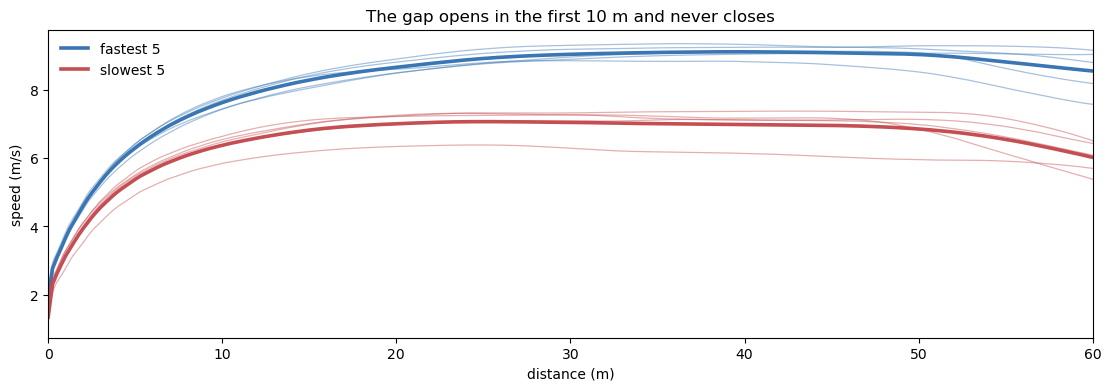

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
for ids, col, label in [(fast_ids, SP.COL_FAST, "fastest 5"), (slow_ids, SP.COL_SLOW, "slowest 5")]:
    for rid in ids:
        r = runs[rid]
        ax.plot(r.distance, r.speed, color=col, lw=0.9, alpha=0.45)
    grid = np.linspace(0, 60, 240)
    mean = np.mean([np.interp(grid, runs[rid].distance, runs[rid].speed) for rid in ids], axis=0)
    ax.plot(grid, mean, color=col, lw=2.6, label=label)
ax.set(xlim=(0, 60), xlabel="distance (m)", ylabel="speed (m/s)",
       title="The gap opens in the first 10 m and never closes")
ax.legend(frameon=False);

## 3 · The bodies at the same instants of the stride

Each group's runners averaged into one representative skeleton (every athlete drawn at 1.75 m so the comparison
is posture, not body size), overlaid at four instants of the top-speed stride. 0 % = right-foot touchdown.

saved /Users/shunchen/Desktop/60m Project Folder/(2) Data (C,P,A)/Pipeline/Figures/fast_vs_slow_demo.png


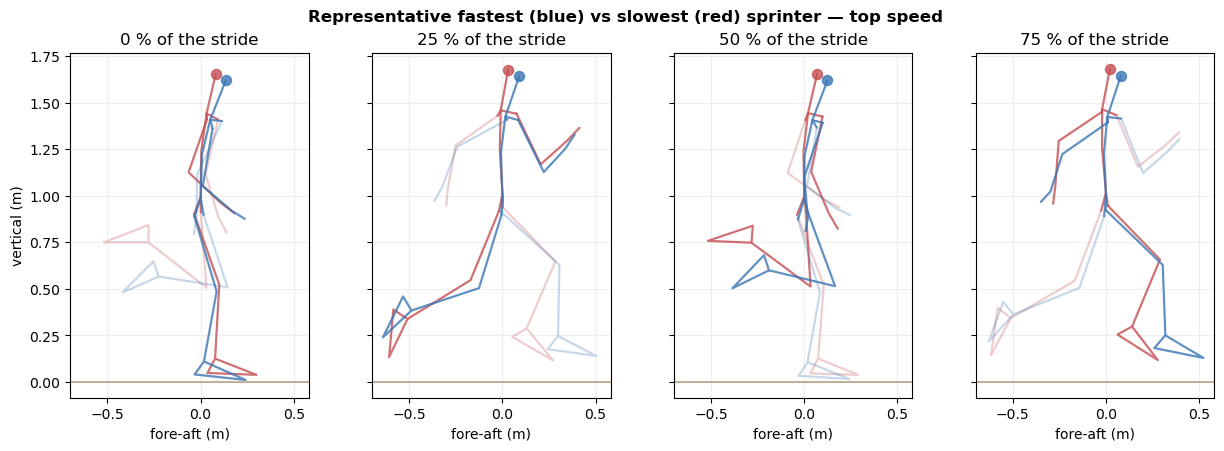

In [4]:
def group_cycle(ids):
    """Mean 64-marker top-speed cycle for a group, each runner height-normalised for drawing."""
    per = []
    for rid in ids:
        run = runs[rid]
        windows = [(a.touchdown, b.touchdown) for a, _m, b in C.top_speed_strides(run)]
        per.append(SP.stride_cycle_raw64(run.trial["raw64"], run.trial["mk"], None,
                                         hscale=SP.height_scale_for(rid, 1.75), windows=windows))
    return np.mean(per, axis=0)

cyc_fast, cyc_slow = group_cycle(fast_ids), group_cycle(slow_ids)
PHASES = (0, 25, 50, 75)
foot = [SP.MK_R_HEEL, SP.MK_L_HEEL, SP.MK_R_TOE, SP.MK_L_TOE]
floor = min(float(c[:, foot, SP._VERT].min()) for c in (cyc_fast, cyc_slow))

fig, axes = plt.subplots(1, len(PHASES), figsize=(3.1 * len(PHASES), 4.4),
                         sharex=True, sharey=True, constrained_layout=True)
for ax, ph in zip(axes, PHASES):
    ax.axhline(0, color="#8a6d3b", lw=1.2, alpha=0.6)
    OUT._draw_raw64(ax, cyc_slow[ph], SP.COL_SLOW, floor=floor, lw=1.6, alpha=0.8)
    OUT._draw_raw64(ax, cyc_fast[ph], SP.COL_FAST, floor=floor, lw=1.6, alpha=0.8)
    ax.set(title=f"{ph} % of the stride", xlabel="fore-aft (m)")
    ax.set_aspect("equal"); ax.grid(alpha=0.2)
axes[0].set_ylabel("vertical (m)")
fig.suptitle("Representative fastest (blue) vs slowest (red) sprinter — top speed", fontweight="bold")
fig.savefig(OUT.FIG_OUT / "fast_vs_slow_demo.png", dpi=200, bbox_inches="tight", facecolor="white")
print(f"saved {OUT.FIG_OUT / 'fast_vs_slow_demo.png'}")

## 4 · Where in the stride the groups separate

The three angle curves with the largest fast-slow gap, on the shared 0–100 % stride axis. Grey band = whole
cohort mean ± 1 SD.

,angle,max_diff_deg,at_%_of_cycle,mean_diff_deg,fast_mean_deg,slow_mean_deg
0,arm_separation,25.6,100,4.4,4.4,-0.1
1,knee_R,-25.0,67,-1.1,62.4,63.6
2,knee_L,-23.1,13,-6.0,61.7,67.7
3,thigh_separation,21.9,55,1.1,0.1,-1.1
4,hip_R,19.4,47,7.8,18.3,10.5


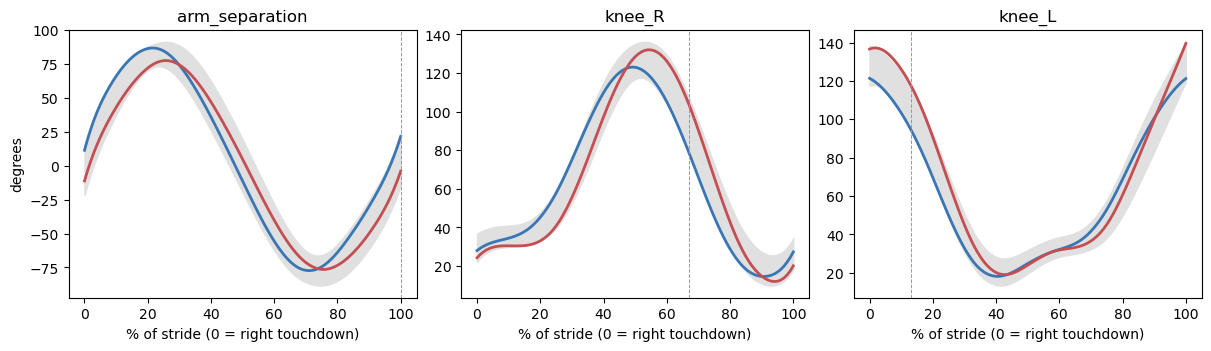

In [5]:
table, fast_c, slow_c, _, _ = SP.fast_vs_slow_angles(cycles, y.to_dict(), n=N)
top3 = table.angle.head(3).tolist()
pct = np.arange(101)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
for ax, name in zip(axes, top3):
    j = SP.ANGLE_NAMES.index(name)
    allc = np.stack([c[:, j] for c in cycles.values()])
    ax.fill_between(pct, allc.mean(0) - allc.std(0), allc.mean(0) + allc.std(0), color="0.88")
    ax.plot(pct, fast_c[:, j], color=SP.COL_FAST, lw=2)
    ax.plot(pct, slow_c[:, j], color=SP.COL_SLOW, lw=2)
    at = int(table.set_index("angle").loc[name, "at_%_of_cycle"])
    ax.axvline(at, color="0.6", lw=0.7, ls="--")
    ax.set(title=name, xlabel="% of stride (0 = right touchdown)")
axes[0].set_ylabel("degrees")
table.head(5)

## 5 · The fair version: fastest vs slowest *within* each sex

Same question with sex removed: fastest 3 vs slowest 3 men, and the same for women.

In [6]:
rows = {}
for s in "MF":
    g = y[F.sex == s].sort_values()
    f3, s3 = list(g.index[-3:]), list(g.index[:3])
    gap = F.loc[f3, cols].mean() - F.loc[s3, cols].mean()
    rows[f"{s}: fast3 − slow3"] = gap
within = pd.DataFrame(rows).round(2)
within

,M: fast3 − slow3,F: fast3 − slow3
top_speed_ms,1.06,1.11
time_to_60m_s,-0.86,-1.19
top_contact_ms,-22.78,-31.67
top_flight_ms,18.89,4.44
top_stride_length_m,0.68,0.16
top_stride_frequency_hz,0.02,0.21
height_m,0.04,-0.03
block_time_s,-0.03,-0.06


## 6 · What the demo shows

* **The race is decided early**: the mean curves separate inside 10 m and run parallel after ~25 m.
* **At top speed the postures are strikingly similar** — the skeleton overlay shows two competent sprinters, not
  two different movements. The visible gaps are degrees, not categories.
* **The biggest pooled angle gaps sit in swing**, consistent with notebook 04's screen — but the within-sex
  table shows the pooled contrast is mostly the sex split wearing a costume: within sex, the gaps shrink and
  the contact-time difference carries most of what remains.
* This is the figure set to lead a talk with; the honest claims behind it live in notebooks 04–06.

In [7]:
assert set(F.sex[fast_ids]) == {"M"} and set(F.sex[slow_ids]) == {"F"}   # the stated confound is real
assert (OUT.FIG_OUT / "fast_vs_slow_demo.png").exists()
assert np.isfinite(cyc_fast).all() and np.isfinite(cyc_slow).all()
print("demo checks passed")

demo checks passed
